<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## D1. Praktikum Deteksi Obyek Dasar
### 1. Import library dan akses Google Drive

In [1]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import drive

# Akses Google Drive
drive.mount('/content/drive')

# Folder gambar sesuai lokasi yang diberikan
IMG_DIR = '/content/drive/MyDrive/PCVK/Images'
print('Folder Images ditemukan:', os.path.isdir(IMG_DIR))


Mounted at /content/drive
Folder Images ditemukan: True


### Persiapan path gambar
Sel ini hanya membantu mencari file di dalam folder `Images` dan subfoldernya (misalnya `facedet` dan `haarcascades`). Metode praktikum tetap dikerjakan pada sel masing-masing.

In [2]:
# Fungsi untuk mencari file berdasarkan nama di dalam folder Images

def cari_file(nama_file, wajib=True):
    nama_file = nama_file.lower()
    for root, dirs, files in os.walk(IMG_DIR):
        for nama in files:
            if nama.lower() == nama_file:
                return os.path.join(root, nama)
    if wajib:
        raise FileNotFoundError(
            f"File {nama_file} tidak ditemukan di {IMG_DIR}. "
            "Periksa nama file dan lokasi folder Images."
        )
    return None


def tampilkan(img, judul='', cmap=None, figsize=(8, 6)):
    plt.figure(figsize=figsize)
    if img is not None and len(img.shape) == 3:
        img_tampil = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        plt.imshow(img_tampil)
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(judul)
    plt.axis('off')
    plt.show()


# Lihat daftar file yang tersedia
for root, dirs, files in os.walk(IMG_DIR):
    print('Folder:', root)
    for nama in files[:30]:
        print(' -', nama)


Folder: /content/drive/MyDrive/PCVK/Images
 - noisy2.png
 - baboon.jpg
 - kitten01.jpg
 - gradient.jpg
 - plat_nomer.jpg
 - lena.jpg
 - ktp_fulan.jpg
 - lena_gs_lc2.jpg
 - lily.jpg
 - djawatan.jpg
 - sudoku-original.jpg
 - Screenshot 2026-10-30 193929.png
 - lena_lc.jpg
 - cats_and_bunnies.jpg
 - cat2_templatejpg.jpg
 - chess-board.jpg
 - laptop.jpg
 - parking-lot-cars.jpg
 - bahrain.jpg
 - bahrain-template.jpg
 - car-park.jpg
 - sudoku.jpg
 - ktm_saya.jpg
Folder: /content/drive/MyDrive/PCVK/Images/haarcascades
 - haarcascade_lowerbody.xml
 - haarcascade_russian_plate_number.xml
 - haarcascade_frontalface_alt2.xml
 - haarcascade_fullbody.xml
 - haarcascade_licence_plate_rus_16stages.xml
 - haarcascade_eye_tree_eyeglasses.xml
 - haarcascade_righteye_2splits.xml
 - haarcascade_frontalcatface.xml
 - haarcascade_lefteye_2splits.xml
 - haarcascade_frontalface_alt.xml
 - haarcascade_eye.xml
 - haarcascade_frontalcatface_extended.xml
 - haarcascade_profileface.xml
 - haarcascade_frontalface_d

### 2. Template Matching dengan 6 metode OpenCV
Gunakan `cats_and_bunnies.jpg` sebagai citra masukan dan `cat2_templatejpg.jpg` sebagai template, sesuai nama pada modul.

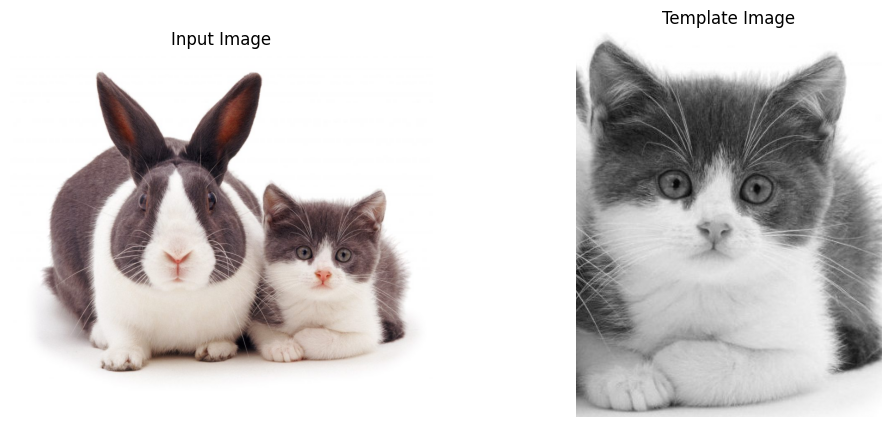

In [3]:
# Membaca citra masukan dan citra template
source_path = cari_file('cats_and_bunnies.jpg')
template_path = cari_file('cat2_templatejpg.jpg', wajib=False)

# Beberapa paket gambar kadang menamai file template dengan titik tambahan
if template_path is None:
    template_path = cari_file('cat2_template.jpg')

source = cv.imread(source_path)
source_gray = cv.cvtColor(source, cv.COLOR_BGR2GRAY)
template = cv.imread(template_path, cv.IMREAD_GRAYSCALE)

if source is None or template is None:
    raise ValueError('Gambar masukan atau template gagal dibaca.')

h, w = template.shape
if h > source_gray.shape[0] or w > source_gray.shape[1]:
    raise ValueError('Ukuran template tidak boleh lebih besar dari citra masukan.')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(source, cv.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('Template Image')
plt.axis('off')
plt.show()


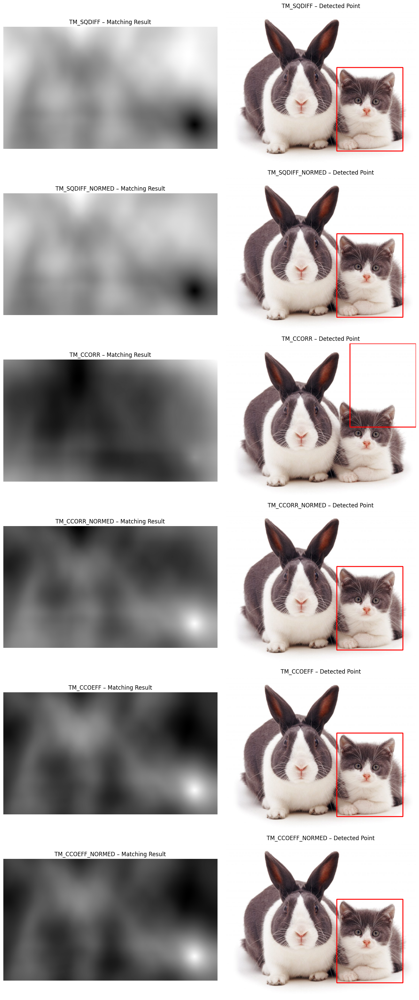

In [4]:
# Enam metode Template Matching pada OpenCV
metode_template = [
    ('TM_SQDIFF', cv.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv.TM_CCORR),
    ('TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED)
]

fig, axes = plt.subplots(6, 2, figsize=(13, 30))
for i, (nama_metode, metode) in enumerate(metode_template):
    hasil = cv.matchTemplate(source_gray, template, metode)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(hasil)

    # Pada metode SQDIFF, nilai minimum adalah lokasi terbaik.
    # Pada empat metode lainnya, nilai maksimum adalah lokasi terbaik.
    lokasi = min_loc if metode in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED] else max_loc

    gambar_kotak = source.copy()
    x, y = lokasi
    cv.rectangle(gambar_kotak, (x, y), (x + w, y + h), (0, 0, 255), 3)

    axes[i, 0].imshow(hasil, cmap='gray')
    axes[i, 0].set_title(nama_metode + ' – Matching Result')
    axes[i, 0].axis('off')

    axes[i, 1].imshow(cv.cvtColor(gambar_kotak, cv.COLOR_BGR2RGB))
    axes[i, 1].set_title(nama_metode + ' – Detected Point')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()


### 3. Template Matching tanpa library OpenCV untuk multiple object
Gunakan `bahrain.jpg` sebagai citra masukan dan `bahrain-template.jpg` sebagai template. Proses pencocokan di bawah ini memakai NumPy dan SciPy, bukan fungsi Template Matching OpenCV.

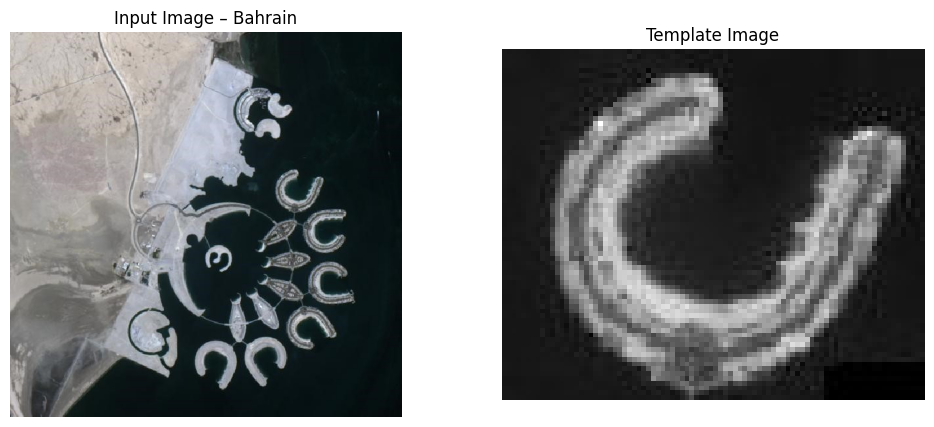

In [5]:
from PIL import Image
from scipy.signal import fftconvolve
from scipy.ndimage import maximum_filter

# Membaca gambar dengan PIL, bukan OpenCV
bahrain_path = cari_file('bahrain.jpg')
bahrain_template_path = cari_file('bahrain-template.jpg')
source_rgb = np.array(Image.open(bahrain_path).convert('RGB'))
template_rgb = np.array(Image.open(bahrain_template_path).convert('RGB'))

# Mengubah RGB menjadi grayscale secara manual
source_manual = (0.299 * source_rgb[:, :, 0] +
                 0.587 * source_rgb[:, :, 1] +
                 0.114 * source_rgb[:, :, 2]).astype(np.float32)
template_manual = (0.299 * template_rgb[:, :, 0] +
                   0.587 * template_rgb[:, :, 1] +
                   0.114 * template_rgb[:, :, 2]).astype(np.float32)

th, tw = template_manual.shape
if th > source_manual.shape[0] or tw > source_manual.shape[1]:
    raise ValueError('Ukuran template lebih besar daripada citra masukan.')

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(source_rgb)
plt.title('Input Image – Bahrain')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(template_manual, cmap='gray')
plt.title('Template Image')
plt.axis('off')
plt.show()


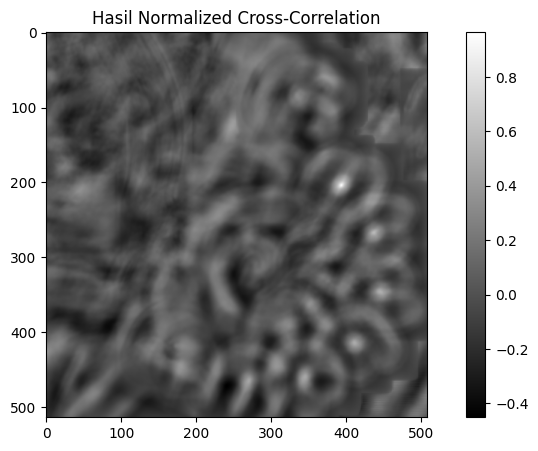

In [6]:
# Menghitung Normalized Cross-Correlation tanpa cv2.matchTemplate
# Template dikurangi nilai rata-ratanya agar terpusat di sekitar nol.
template_pusat = template_manual - np.mean(template_manual)

# Pembilang korelasi dihitung menggunakan FFT convolution.
pembilang = fftconvolve(source_manual, template_pusat[::-1, ::-1], mode='valid')

# Integral image untuk menghitung jumlah dan jumlah kuadrat setiap jendela.
jumlah_area = np.cumsum(np.cumsum(source_manual, axis=0), axis=1)
jumlah_kuadrat = np.cumsum(np.cumsum(source_manual ** 2, axis=0), axis=1)

# Tambahkan baris dan kolom nol agar perhitungan area lebih mudah.
jumlah_area = np.pad(jumlah_area, ((1, 0), (1, 0)), mode='constant')
jumlah_kuadrat = np.pad(jumlah_kuadrat, ((1, 0), (1, 0)), mode='constant')

jumlah_patch = (jumlah_area[th:, tw:] - jumlah_area[:-th, tw:]
                - jumlah_area[th:, :-tw] + jumlah_area[:-th, :-tw])
jumlah_patch_kuadrat = (jumlah_kuadrat[th:, tw:] - jumlah_kuadrat[:-th, tw:]
                        - jumlah_kuadrat[th:, :-tw] + jumlah_kuadrat[:-th, :-tw])

n_pixel = th * tw
variansi_patch = np.maximum(jumlah_patch_kuadrat - (jumlah_patch ** 2 / n_pixel), 0)
energi_template = np.sum(template_pusat ** 2)
pembagi = np.sqrt(variansi_patch * energi_template)

hasil_ncc = np.zeros_like(pembilang, dtype=np.float32)
valid = pembagi > 1e-8
hasil_ncc[valid] = pembilang[valid] / pembagi[valid]

plt.figure(figsize=(10, 5))
plt.imshow(hasil_ncc, cmap='gray')
plt.title('Hasil Normalized Cross-Correlation')
plt.colorbar()
plt.show()


Jumlah objek terdeteksi: 2
Nilai kecocokan: [0.964, 0.576]


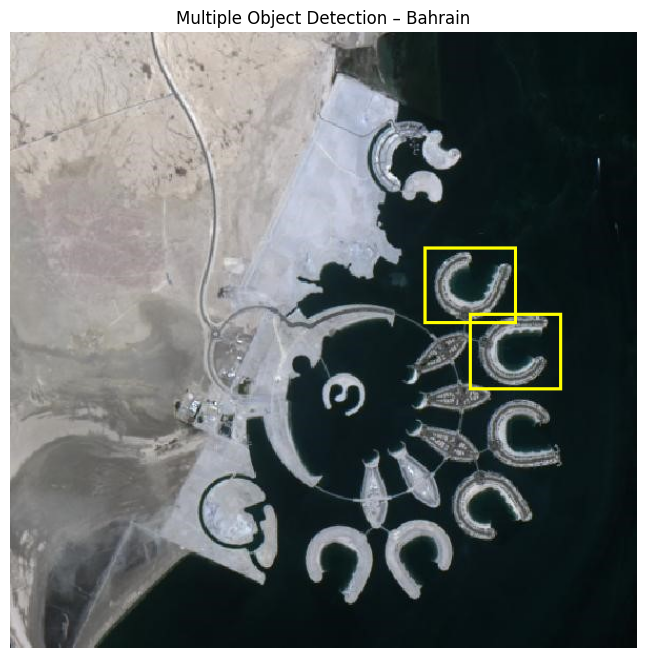

In [7]:
# Mencari beberapa objek berdasarkan nilai kecocokan dan menghindari kotak bertumpuk
threshold = 0.55  # Naikkan jika terlalu banyak deteksi, turunkan jika belum ada deteksi
ukuran_filter = (max(3, th // 2), max(3, tw // 2))
local_max = maximum_filter(hasil_ncc, size=ukuran_filter)
koordinat = np.argwhere((hasil_ncc == local_max) & (hasil_ncc >= threshold))
koordinat = sorted(koordinat, key=lambda p: hasil_ncc[p[0], p[1]], reverse=True)

pilihan = []
for y, x in koordinat:
    # Non-maximum suppression sederhana untuk menghindari kotak yang saling menumpuk.
    terlalu_dekat = any(abs(x - x0) < tw * 0.6 and abs(y - y0) < th * 0.6
                        for x0, y0, nilai in pilihan)
    if not terlalu_dekat:
        pilihan.append((x, y, float(hasil_ncc[y, x])))

hasil_gambar = source_rgb.copy()
for x, y, nilai in pilihan:
    from PIL import ImageDraw
    gambar_pil = Image.fromarray(hasil_gambar)
    draw = ImageDraw.Draw(gambar_pil)
    draw.rectangle([x, y, x + tw, y + th], outline='yellow', width=3)
    hasil_gambar = np.array(gambar_pil)

print('Jumlah objek terdeteksi:', len(pilihan))
print('Nilai kecocokan:', [round(v, 3) for x, y, v in pilihan])
plt.figure(figsize=(10, 8))
plt.imshow(hasil_gambar)
plt.title('Multiple Object Detection – Bahrain')
plt.axis('off')
plt.show()


### 4a. Sobel Edge Detection
Gunakan gambar `car-park.jpg`.

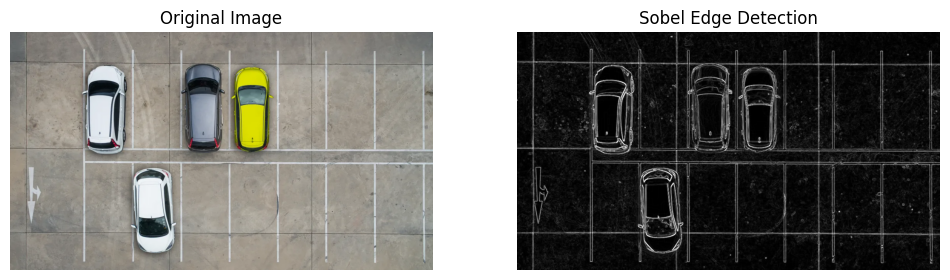

In [8]:
car_path = cari_file('car-park.jpg')
car = cv.imread(car_path)
car_gray = cv.cvtColor(car, cv.COLOR_BGR2GRAY)

sobel_x = cv.Sobel(car_gray, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(car_gray, cv.CV_64F, 0, 1, ksize=3)
sobel_x = cv.convertScaleAbs(sobel_x)
sobel_y = cv.convertScaleAbs(sobel_y)
sobel_gabungan = cv.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(sobel_gabungan, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('off')
plt.show()


### 4b. Canny Edge Detection

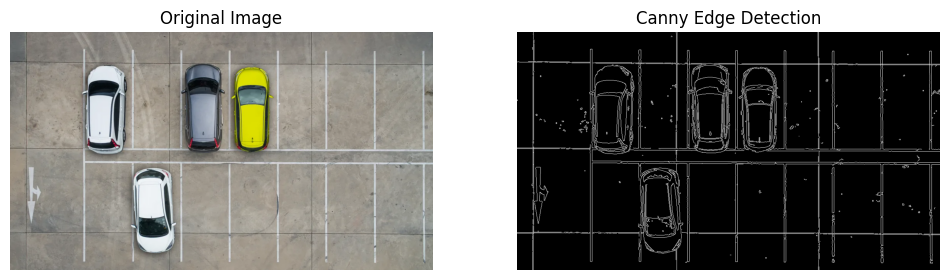

In [9]:
# Menggunakan citra car-park yang sama
canny = cv.Canny(car_gray, 100, 200)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()


### 4c. Laplacian Edge Detection
Sesuai teori modul, gambar dihaluskan terlebih dahulu dengan Gaussian Filter sebelum menerapkan Laplacian.

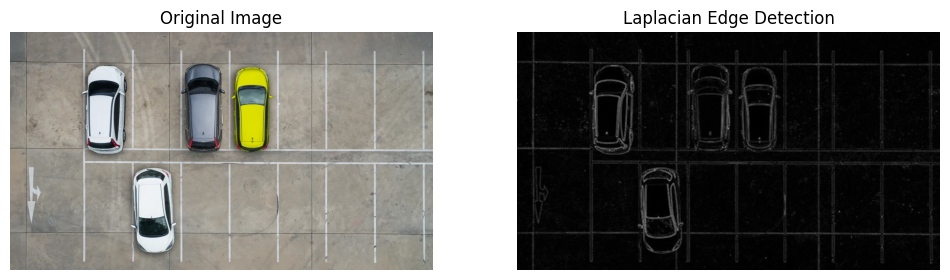

In [10]:
car_blur = cv.GaussianBlur(car_gray, (3, 3), 0)
laplacian = cv.Laplacian(car_blur, cv.CV_64F)
laplacian = cv.convertScaleAbs(laplacian)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(car, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')
plt.show()


### 5a. Harris Corner Detection
Gunakan gambar `chess-board.jpg`.

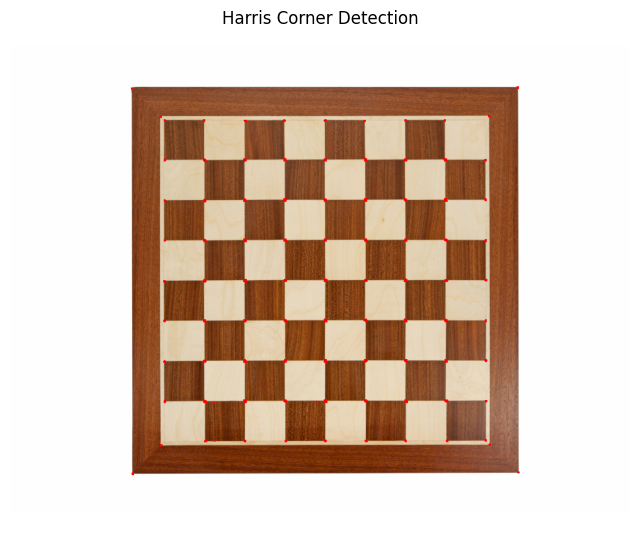

In [11]:
chess_path = cari_file('chess-board.jpg')
chess = cv.imread(chess_path)
chess_gray = cv.cvtColor(chess, cv.COLOR_BGR2GRAY)

chess_float = np.float32(chess_gray)
harris = cv.cornerHarris(chess_float, 2, 3, 0.04)
harris = cv.dilate(harris, None)

harris_result = chess.copy()
harris_result[harris > 0.01 * harris.max()] = [0, 0, 255]

tampilkan(harris_result, 'Harris Corner Detection', figsize=(8, 8))


### 5b. Shi-Tomasi Corner Detection

Jumlah sudut terdeteksi: 100


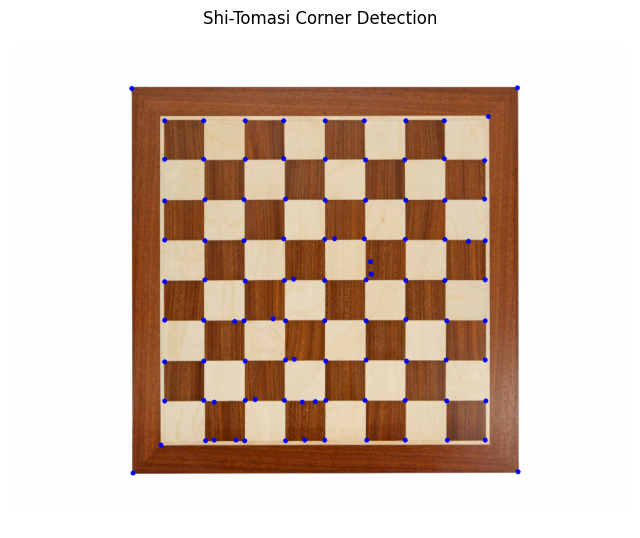

In [12]:
shi_tomasi = cv.goodFeaturesToTrack(
    chess_gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10
)

shi_result = chess.copy()
if shi_tomasi is not None:
    shi_tomasi = np.intp(shi_tomasi)
    for corner in shi_tomasi:
        x, y = corner.ravel()
        cv.circle(shi_result, (x, y), 4, (255, 0, 0), -1)

print('Jumlah sudut terdeteksi:', 0 if shi_tomasi is None else len(shi_tomasi))
tampilkan(shi_result, 'Shi-Tomasi Corner Detection', figsize=(8, 8))


### 6. Grid Detection dengan Hough Transform
Gunakan gambar `sudoku.jpg`. Tahapannya mengikuti teori modul: Canny, dilasi, erosi, HoughLines, lalu menggabungkan garis yang mirip.

Jumlah kandidat Hough: 32
Jumlah garis setelah penggabungan: 11
Jumlah garis yang ditampilkan: 10


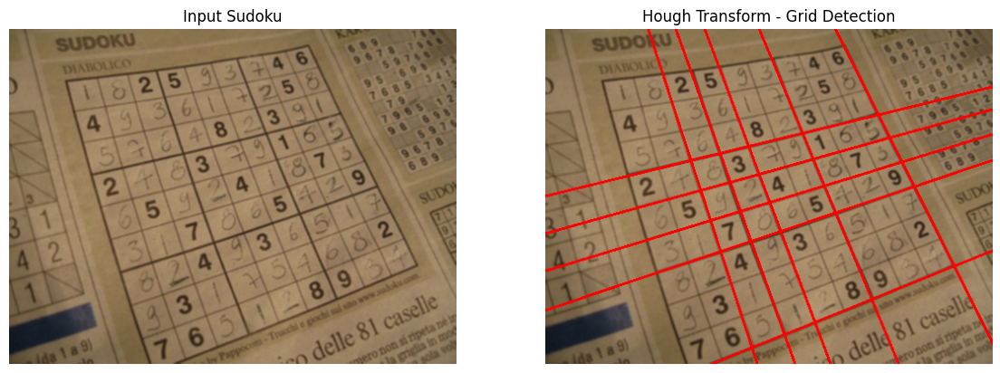

In [13]:
sudoku_path = cari_file('sudoku.jpg')
sudoku = cv.imread(sudoku_path)

if sudoku is None:
    raise FileNotFoundError('Gambar sudoku.jpg tidak ditemukan atau gagal dibaca.')

sudoku_gray = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)

# Menghaluskan gambar agar tekstur angka dan tulisan tidak terlalu banyak terdeteksi
sudoku_blur = cv.GaussianBlur(sudoku_gray, (5, 5), 1.2)

# 1. Canny Edge Detection
sudoku_edges = cv.Canny(sudoku_blur, 50, 150, apertureSize=3)

# 2. Dilasi gambar tepi
kernel_grid = np.ones((3, 3), np.uint8)
sudoku_dilasi = cv.dilate(sudoku_edges, kernel_grid, iterations=1)

# 3. Erosi gambar tepi
sudoku_proses = cv.erode(sudoku_dilasi, kernel_grid, iterations=1)

# 4. HoughLines
# Ambang dibuat mengikuti ukuran gambar supaya garis-garis lemah tidak menumpuk.
tinggi, lebar = sudoku.shape[:2]
hough_threshold = max(100, int(min(tinggi, lebar) * 0.50))
lines = cv.HoughLines(sudoku_proses, 1, np.pi / 180, hough_threshold)

# 5. Menggabungkan garis yang memiliki rho dan theta hampir sama
kelompok_garis = []
rho_tolerance = max(14, min(20, int(min(tinggi, lebar) * 0.06)))
theta_tolerance = np.deg2rad(3)

if lines is not None:
    for baris in lines:
        rho, theta = baris[0]

        # Menyamakan arah garis agar garis yang sama bisa dibandingkan.
        if theta >= np.pi / 2:
            rho = -rho
            theta = theta - np.pi

        ditemukan = False
        for kelompok in kelompok_garis:
            rho_rata, theta_rata, jumlah = kelompok

            if (abs(rho - rho_rata) < rho_tolerance and
                    abs(theta - theta_rata) < theta_tolerance):
                kelompok[0] = (rho_rata * jumlah + rho) / (jumlah + 1)
                kelompok[1] = (theta_rata * jumlah + theta) / (jumlah + 1)
                kelompok[2] = jumlah + 1
                ditemukan = True
                break

        if not ditemukan:
            kelompok_garis.append([rho, theta, 1])

# Mengutamakan kelompok yang didukung lebih dari satu kandidat Hough.
# Jika kandidat terlalu sedikit, gunakan semua kelompok yang ditemukan.
kelompok_utama = [kelompok for kelompok in kelompok_garis if kelompok[2] >= 2]
if len(kelompok_utama) < 4:
    kelompok_utama = kelompok_garis

sudoku_hough = sudoku.copy()
for rho, theta, jumlah in kelompok_utama:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    panjang = max(tinggi, lebar) * 2

    titik1 = (int(x0 + panjang * (-b)), int(y0 + panjang * a))
    titik2 = (int(x0 - panjang * (-b)), int(y0 - panjang * a))
    cv.line(sudoku_hough, titik1, titik2, (0, 0, 255), 2)

print('Jumlah kandidat Hough:', 0 if lines is None else len(lines))
print('Jumlah garis setelah penggabungan:', len(kelompok_garis))
print('Jumlah garis yang ditampilkan:', len(kelompok_utama))

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(sudoku, cv.COLOR_BGR2RGB))
plt.title('Input Sudoku')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(sudoku_hough, cv.COLOR_BGR2RGB))
plt.title('Hough Transform - Grid Detection')
plt.axis('off')
plt.show()


### 7. Contour Detection dengan `findContours()`
Gunakan gambar `laptop.jpg`.

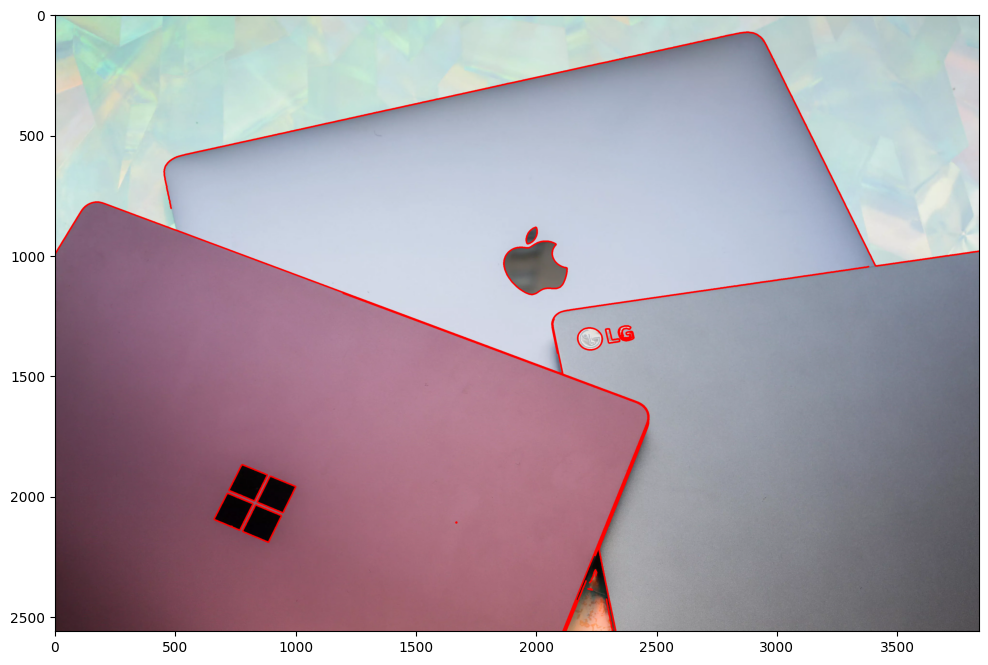

In [14]:
laptop_bgr = cv.imread('/content/drive/MyDrive/PCVK/Images/laptop.jpg')
laptop_rgb = cv.cvtColor(laptop_bgr, cv.COLOR_BGR2RGB)
laptop_gray = cv.cvtColor(laptop_bgr, cv.COLOR_BGR2GRAY)

# 1. Ubah citra input menjadi biner dengan Canny edge detection
blur_laptop = cv.GaussianBlur(laptop_gray, (5, 5), 0)
edges_laptop = cv.Canny(blur_laptop, 50, 150)

# 2. Menemukan kontur menggunakan findContours()
contours, hierarchy = cv.findContours(edges_laptop, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# 3. Menggambarkan kontur pada citra input menggunakan drawContours()
hasil_kontur = laptop_rgb.copy()
cv.drawContours(hasil_kontur, contours, -1, (255, 0, 0), 6)

plt.figure(figsize=(12, 8))
plt.imshow(hasil_kontur)
plt.show()

## D2. Praktikum Feature Matching dan Face Detection
### Persiapan Haar Cascade

In [15]:
# Mencari file Haar Cascade di folder Images terlebih dahulu.
# Jika tidak ada, gunakan file bawaan OpenCV.

def cari_cascade(nama_xml):
    path = cari_file(nama_xml, wajib=False)
    if path is not None:
        return path
    path_bawaan = os.path.join(cv.data.haarcascades, nama_xml)
    if os.path.exists(path_bawaan):
        return path_bawaan
    return None

face_xml = cari_cascade('haarcascade_frontalface_alt.xml')
if face_xml is None:
    face_xml = cari_cascade('haarcascade_frontalface_default.xml')
if face_xml is None:
    raise FileNotFoundError('File Haar Cascade untuk wajah tidak ditemukan.')

face_cascade = cv.CascadeClassifier(face_xml)
if face_cascade.empty():
    raise ValueError('Haar Cascade wajah gagal dimuat.')

print('Haar Cascade wajah:', face_xml)


Haar Cascade wajah: /content/drive/MyDrive/PCVK/Images/haarcascades/haarcascade_frontalface_alt.xml


### 8. Face Detection pada gambar lain di folder `facedet`
Seluruh gambar yang tersedia di folder `Images/facedet` akan diproses satu per satu. Sesuai contoh modul, gambar kucing bisa saja belum terdeteksi pada tahap ini.

Jumlah gambar: 10
jokowi.jpg - jumlah wajah: 1


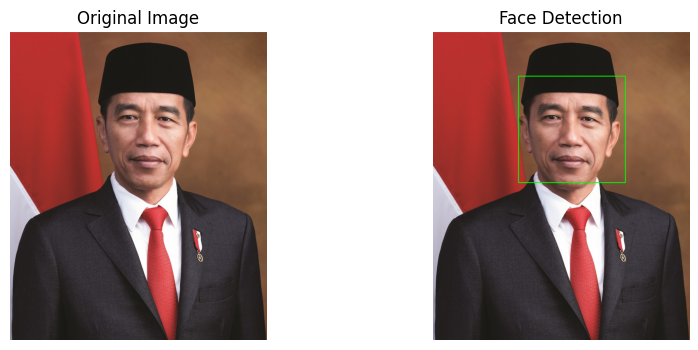

kartini.jpg - jumlah wajah: 1


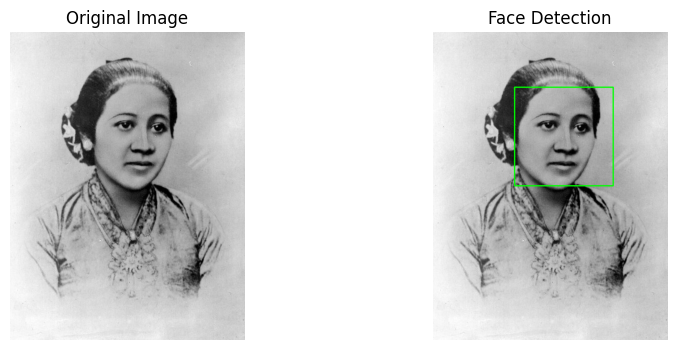

kucing.jpg - jumlah wajah: 0


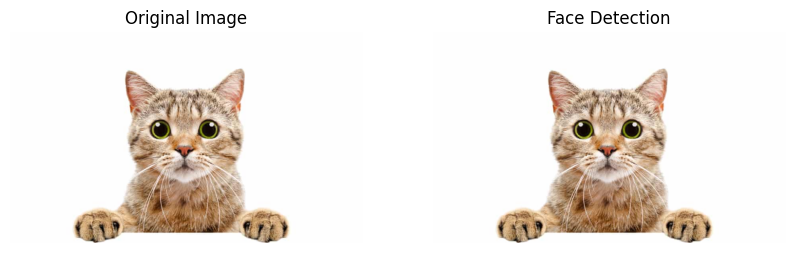

many_cereals.jpg - jumlah wajah: 0


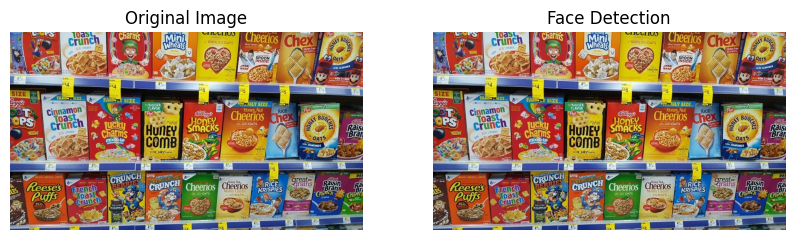

mask.png - jumlah wajah: 5


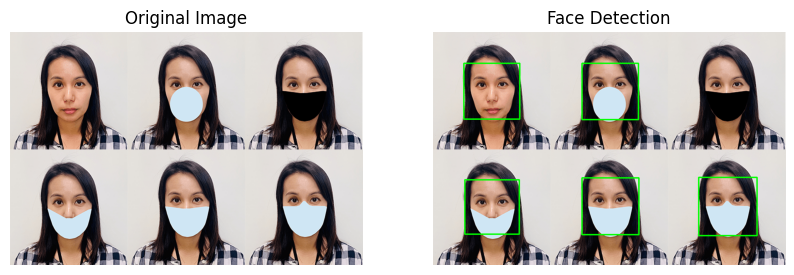

mjordan.jpg - jumlah wajah: 1


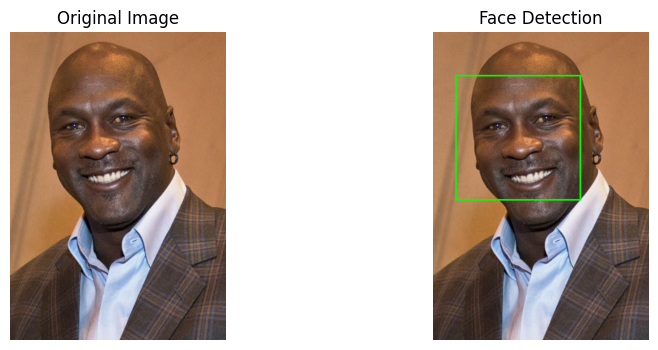

people.jpg - jumlah wajah: 9


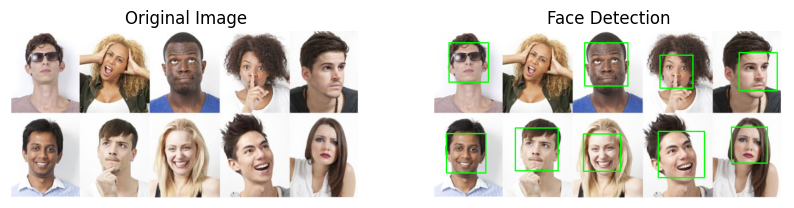

prabowo.jpg - jumlah wajah: 1


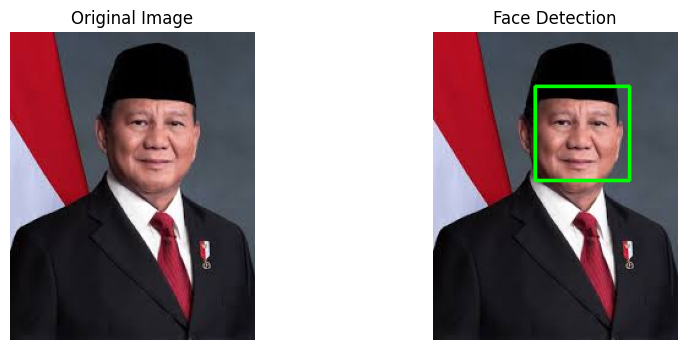

reeses_puffs.png - jumlah wajah: 0


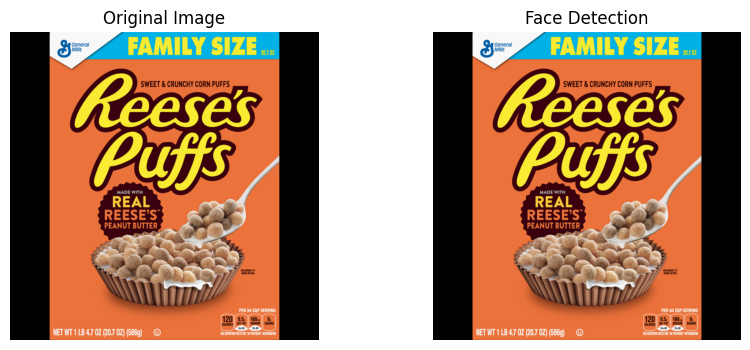

solvayconf.jpg - jumlah wajah: 27


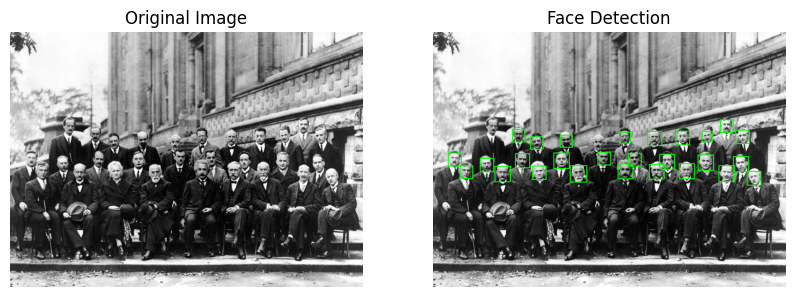

In [16]:
FACEDET_DIR = os.path.join(IMG_DIR, 'facedet')
if not os.path.isdir(FACEDET_DIR):
    # Cari folder facedet jika nama folder berada pada subfolder lain.
    FACEDET_DIR = None
    for root, dirs, files in os.walk(IMG_DIR):
        for nama_dir in dirs:
            if nama_dir.lower() == 'facedet':
                FACEDET_DIR = os.path.join(root, nama_dir)
                break
        if FACEDET_DIR:
            break

if FACEDET_DIR is None:
    raise FileNotFoundError('Folder facedet tidak ditemukan di dalam Images.')

file_gambar = [os.path.join(FACEDET_DIR, f) for f in os.listdir(FACEDET_DIR)
               if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
print('Jumlah gambar:', len(file_gambar))

for path_gambar in sorted(file_gambar):
    gambar = cv.imread(path_gambar)
    if gambar is None:
        print('Gagal membaca:', path_gambar)
        continue
    gray = cv.cvtColor(gambar, cv.COLOR_BGR2GRAY)
    wajah = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(25, 25)
    )
    hasil = gambar.copy()
    for (x, y, w, h) in wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

    print(os.path.basename(path_gambar), '- jumlah wajah:', len(wajah))
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(gambar, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    plt.title('Face Detection')
    plt.axis('off')
    plt.show()


### 9. Face Detection pada wajah kucing
Gunakan Haar Cascade khusus wajah kucing. Jika XML belum tersedia pada folder gambar atau instalasi OpenCV, sel ini mengunduh file cascade kucing.

Gambar kucing: kucing.jpg
Jumlah wajah kucing terdeteksi: 2


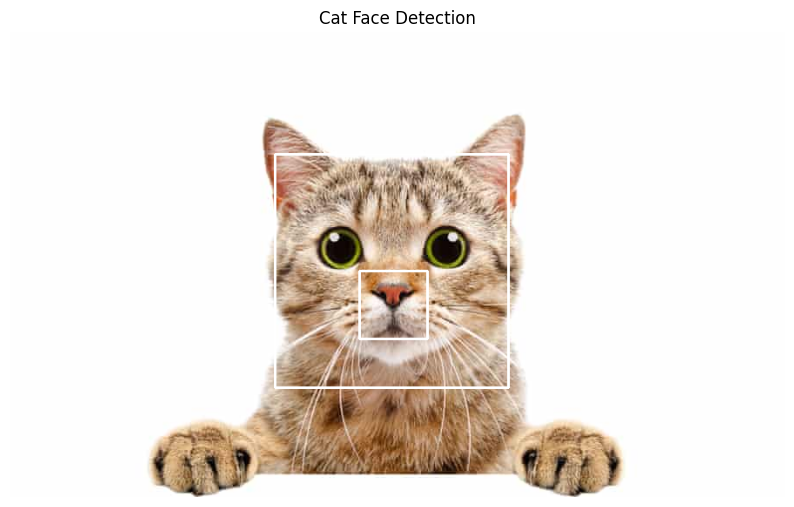

In [17]:
import urllib.request

cat_xml_path = cari_file('haarcascade_frontalcatface.xml', wajib=False)
if cat_xml_path is None:
    cat_xml_path = os.path.join(IMG_DIR, 'haarcascade_frontalcatface.xml')
    url_cat_xml = 'https://raw.githubusercontent.com/austinjoyal/haar-cascade-files/master/haarcascade_frontalcatface.xml'
    urllib.request.urlretrieve(url_cat_xml, cat_xml_path)

cat_cascade = cv.CascadeClassifier(cat_xml_path)
if cat_cascade.empty():
    raise ValueError('Haar Cascade wajah kucing gagal dimuat.')

# Mengambil gambar kucing dari folder facedet
kandidat_kucing = [p for p in file_gambar
                   if ('cat' in os.path.basename(p).lower() or
                       'kucing' in os.path.basename(p).lower())]
if not kandidat_kucing:
    print('File gambar kucing tidak ditemukan otomatis. Isi file_gambar:')
    print([os.path.basename(p) for p in file_gambar])
    raise FileNotFoundError('Tentukan path gambar kucing dari folder facedet.')

cat_path = kandidat_kucing[0]
cat_image = cv.imread(cat_path)
cat_gray = cv.cvtColor(cat_image, cv.COLOR_BGR2GRAY)
cat_faces = cat_cascade.detectMultiScale(
    cat_gray, scaleFactor=1.05, minNeighbors=3, minSize=(40, 40)
)
cat_result = cat_image.copy()
for (x, y, w, h) in cat_faces:
    cv.rectangle(cat_result, (x, y), (x + w, y + h), (255, 255, 255), 2)

print('Gambar kucing:', os.path.basename(cat_path))
print('Jumlah wajah kucing terdeteksi:', len(cat_faces))
tampilkan(cat_result, 'Cat Face Detection', figsize=(10, 7))


### 10. Eyes Detection pada wajah Pak Prabowo

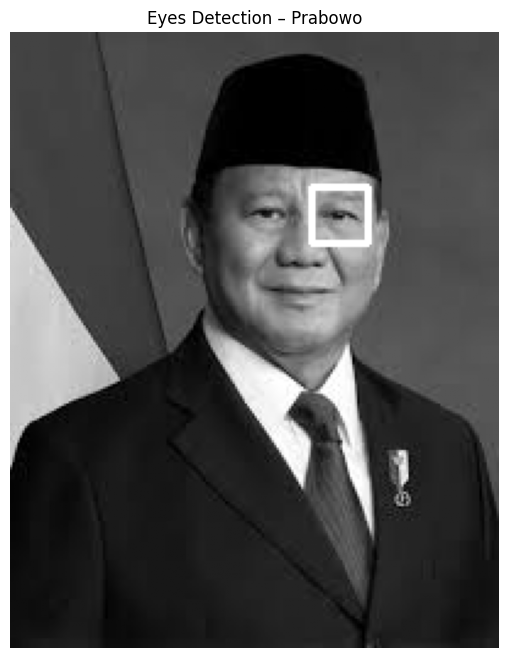

In [18]:
prabowo_path = cari_file('prabowo.jpg')
prabowo_gray = cv.imread(prabowo_path, cv.IMREAD_GRAYSCALE)
if prabowo_gray is None:
    raise ValueError('Gambar prabowo.jpg gagal dibaca.')

eye_xml = cari_cascade('haarcascade_eye.xml')
if eye_xml is None:
    raise FileNotFoundError('haarcascade_eye.xml tidak ditemukan.')
eye_cascade = cv.CascadeClassifier(eye_xml)

wajah_prabowo = face_cascade.detectMultiScale(
    prabowo_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
)
prabowo_hasil = prabowo_gray.copy()
for (x, y, w, h) in wajah_prabowo:
    roi_wajah = prabowo_gray[y:y+h, x:x+w]
    mata = eye_cascade.detectMultiScale(
        roi_wajah, scaleFactor=1.1, minNeighbors=5, minSize=(10, 10)
    )
    for (mx, my, mw, mh) in mata:
        cv.rectangle(prabowo_hasil, (x+mx, y+my),
                     (x+mx+mw, y+my+mh), 255, 2)

tampilkan(prabowo_hasil, 'Eyes Detection – Prabowo', cmap='gray', figsize=(8, 8))


### 11. Deteksi senyuman pada gambar `people`

Jumlah wajah: 9
Jumlah kandidat senyuman: 0


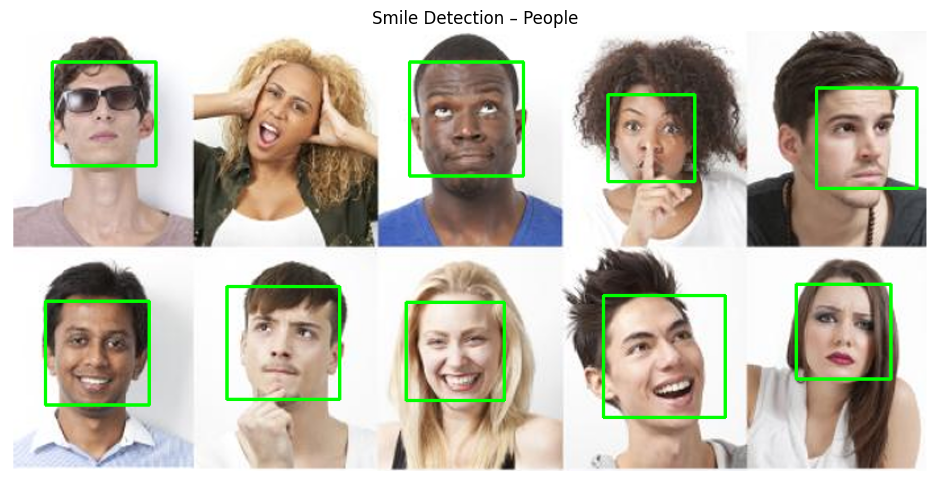

In [19]:
people_path = cari_file('people.jpg')
people = cv.imread(people_path)
people_gray = cv.cvtColor(people, cv.COLOR_BGR2GRAY)

smile_xml = cari_cascade('haarcascade_smile.xml')
if smile_xml is None:
    raise FileNotFoundError('haarcascade_smile.xml tidak ditemukan.')
smile_cascade = cv.CascadeClassifier(smile_xml)

people_result = people.copy()
people_faces = face_cascade.detectMultiScale(
    people_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
)
jumlah_senyum = 0
for (x, y, w, h) in people_faces:
    cv.rectangle(people_result, (x, y), (x+w, y+h), (0, 255, 0), 2)
    # Area bawah wajah digunakan untuk mencari senyuman.
    roi_gray = people_gray[y + h//2:y + h, x:x+w]
    roi_color = people_result[y + h//2:y + h, x:x+w]
    senyum = smile_cascade.detectMultiScale(
        roi_gray, scaleFactor=1.7, minNeighbors=20, minSize=(15, 15)
    )
    jumlah_senyum += len(senyum)
    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)

print('Jumlah wajah:', len(people_faces))
print('Jumlah kandidat senyuman:', jumlah_senyum)
tampilkan(people_result, 'Smile Detection – People', figsize=(12, 8))


### 12. Face Tracking menggunakan Google Colab
Google Colab tidak memakai `cv.VideoCapture(0)` secara langsung untuk kamera laptop. Sel ini meminta izin kamera dari browser, mengambil frame berulang kali, lalu mendeteksi wajah menggunakan Haar Cascade.

Jalankan sel ini dan izinkan akses kamera. Tekan tombol **Stop** pada output sel untuk menghentikan proses jika tersedia, atau hentikan eksekusi sel dari Colab.

In [20]:
from IPython.display import display, Javascript, clear_output
from google.colab.output import eval_js
from base64 import b64decode
import time

# Menyiapkan fungsi JavaScript untuk membuka kamera dan mengambil frame.
display(Javascript(r"""
window.startFaceCamera = async function() {
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  const video = document.createElement('video');
  video.style.display = 'none';
  video.srcObject = stream;
  document.body.appendChild(video);
  await video.play();
  window.faceVideo = video;
  window.faceStream = stream;
  window.faceCanvas = document.createElement('canvas');
  window.faceCanvas.width = video.videoWidth;
  window.faceCanvas.height = video.videoHeight;
  return [video.videoWidth, video.videoHeight];
};

window.captureFaceFrame = function() {
  const video = window.faceVideo;
  const canvas = window.faceCanvas;
  canvas.getContext('2d').drawImage(video, 0, 0, canvas.width, canvas.height);
  return canvas.toDataURL('image/jpeg', 0.8);
};

window.stopFaceCamera = function() {
  if (window.faceStream) {
    window.faceStream.getTracks().forEach(track => track.stop());
  }
  if (window.faceVideo) window.faceVideo.remove();
  return 'Kamera dihentikan';
};
"""))

ukuran_kamera = eval_js('window.startFaceCamera()')
print('Resolusi kamera:', ukuran_kamera)

try:
    # Jumlah frame dapat ditambah sesuai kebutuhan.
    for i in range(100):
        frame_data = eval_js('window.captureFaceFrame()')
        frame_bytes = b64decode(frame_data.split(',')[1])
        frame = cv.imdecode(np.frombuffer(frame_bytes, np.uint8), cv.IMREAD_COLOR)
        frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        wajah_live = face_cascade.detectMultiScale(
            frame_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
        )
        for (x, y, w, h) in wajah_live:
            cv.rectangle(frame, (x, y), (x+w, y+h), (0, 255, 0), 2)

        clear_output(wait=True)
        plt.figure(figsize=(7, 5))
        plt.imshow(cv.cvtColor(frame, cv.COLOR_BGR2RGB))
        plt.title('Face Tracking – Frame {}'.format(i + 1))
        plt.axis('off')
        plt.show()
        time.sleep(0.05)
finally:
    eval_js('window.stopFaceCamera()')


<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied

### 13. Blurring pada bagian wajah yang terdeteksi
Petunjuk modul menggunakan `cv.medianBlur`. Contoh ini memakai `prabowo.jpg`; nama gambar dapat diganti dengan gambar lain yang memiliki wajah.

Jumlah wajah yang diblur: 1


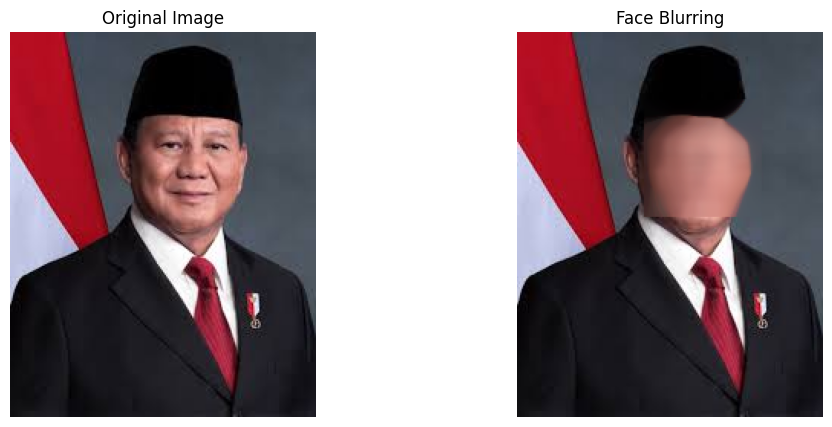

In [21]:
blur_path = cari_file('prabowo.jpg')
blur_image = cv.imread(blur_path)
blur_gray = cv.cvtColor(blur_image, cv.COLOR_BGR2GRAY)

blur_faces = face_cascade.detectMultiScale(
    blur_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
)
blur_result = blur_image.copy()

for (x, y, w, h) in blur_faces:
    roi = blur_result[y:y+h, x:x+w]
    # Median Blur harus menggunakan ukuran kernel ganjil.
    kernel_blur = 31 if min(w, h) >= 31 else max(3, (min(w, h) // 2) * 2 + 1)
    roi_blur = cv.medianBlur(roi, kernel_blur)
    blur_result[y:y+h, x:x+w] = roi_blur

print('Jumlah wajah yang diblur:', len(blur_faces))
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(blur_image, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blur_result, cv.COLOR_BGR2RGB))
plt.title('Face Blurring')
plt.axis('off')
plt.show()


### 14a. Menampilkan gambar KTM
Siapkan foto/scan KTM milik sendiri di folder `Images` dengan nama `ktm_saya.jpg`. Gunakan foto yang jelas dan lurus.

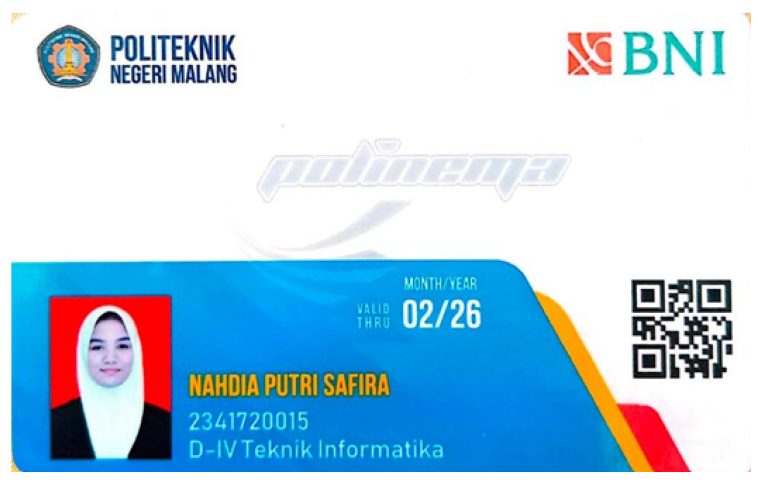

In [32]:
path_ktm = '/content/drive/MyDrive/PCVK/Images/ktm_saya.jpg'

ktm = cv2.imread(path_ktm)

if ktm is None:
    raise FileNotFoundError("Gambar KTM tidak ditemukan!")

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(ktm, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

### 14b. Menampilkan foto pada KTM
Isi koordinat `x`, `y`, `w`, dan `h` sesuai posisi foto pada KTM milikmu. Koordinat awal `(0, 0)` berada di pojok kiri atas gambar.

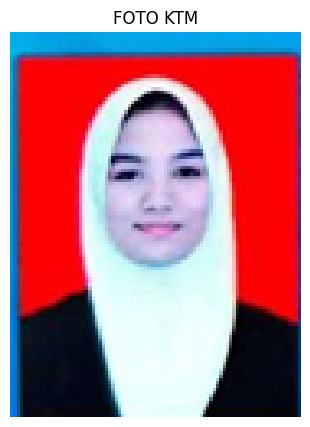

In [31]:
# Mengambil ukuran gambar KTM
h, w = ktm.shape[:2]

# Crop bagian foto KTM
foto_ktm = ktm[
    int(0.60 * h):int(0.96 * h),
    int(0.05 * w):int(0.22 * w)
]

# Menampilkan foto KTM
plt.figure(figsize=(5, 5))
plt.title('FOTO KTM')
plt.imshow(cv2.cvtColor(foto_ktm, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

### 14c. Deteksi obyek KTM dengan Feature Matching
Siapkan foto kedua yang menampilkan KTM bersama barang lain, simpan di folder `Images` dengan nama `ktm_bersama_barang.jpg`. KTM pada foto kedua akan dicocokkan dengan gambar KTM pada nomor 14a menggunakan SIFT dan Brute-Force Matching dengan ratio test.

Jumlah fitur yang cocok: 409
KTM berhasil dideteksi!


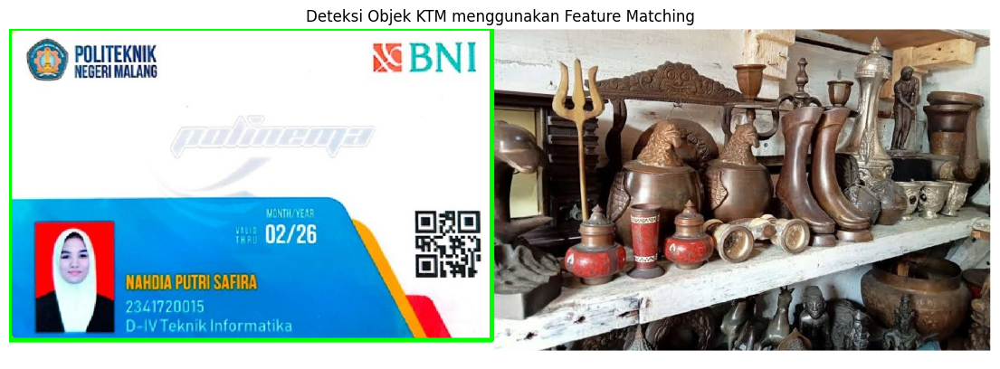

In [33]:
# Membaca gambar KTM sebagai template
ktm = cv2.imread(
    '/content/drive/MyDrive/PCVK/Images/ktm_saya.jpg',
    cv2.IMREAD_GRAYSCALE
)

# Membaca gambar KTM bersama barang lain
gambar = cv2.imread(
    '/content/drive/MyDrive/PCVK/Images/ktm_bersama_barang.jpg'
)

if ktm is None or gambar is None:
    raise FileNotFoundError("Pastikan kedua gambar tersedia!")

gambar_gray = cv2.cvtColor(gambar, cv2.COLOR_BGR2GRAY)

# Membuat SIFT Descriptor
sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(ktm, None)
kp2, des2 = sift.detectAndCompute(gambar_gray, None)

# Brute Force Matching
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

# Ratio Test
good = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good.append(m)

print("Jumlah fitur yang cocok:", len(good))

# Feature Matching
if len(good) >= 4:

    src_pts = np.float32(
        [kp1[m.queryIdx].pt for m in good]
    ).reshape(-1, 1, 2)

    dst_pts = np.float32(
        [kp2[m.trainIdx].pt for m in good]
    ).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        5.0
    )

    if M is not None:

        h, w = ktm.shape

        pts = np.float32([
            [0, 0],
            [0, h - 1],
            [w - 1, h - 1],
            [w - 1, 0]
        ]).reshape(-1, 1, 2)

        dst = cv2.perspectiveTransform(pts, M)

        jumlah_inlier = int(mask.sum())

        if jumlah_inlier >= 8:

            cv2.polylines(
                gambar,
                [np.int32(dst)],
                True,
                (0, 255, 0),
                5
            )

            print("KTM berhasil dideteksi!")

        else:
            print("Kecocokan fitur belum mencukupi.")

    else:
        print("Objek KTM tidak berhasil ditemukan.")

else:
    print("Fitur yang cocok terlalu sedikit.")

# Menampilkan hasil deteksi
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB))
plt.title('Deteksi Objek KTM menggunakan Feature Matching')
plt.axis('off')
plt.show()

## D3. Tugas Pengayaan – Pengenalan Karakter KTM dengan CNN (Opsional)
Bagian ini terpisah dari D1 dan D2. Sesuai modul, siapkan dataset dengan satu folder untuk setiap karakter (misalnya `0` sampai `9`, dan bila diperlukan `A` sampai `Z`). Setiap folder berisi hasil crop karakter yang sesuai.

Struktur folder:

```text
dataset/
  training/
    0/ ...gambar angka nol...
    1/ ...gambar angka satu...
    ...
    9/ ...gambar angka sembilan...
  testing/
    KTM_1/ ...potongan karakter berurutan...
```

### D3.1 Persiapan data training

In [43]:
import os
import cv2 as cv
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = '/content/drive/MyDrive/PCVK/Images/dataset/training'

width, height = 100, 100
dirs = sorted(os.listdir(DATADIR))

training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)

    for img in tqdm(os.listdir(path)):
        try:
            img_array = cv.imread(
                os.path.join(path, img),
                cv.IMREAD_GRAYSCALE
            )

            if img_array is None:
                continue

            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])

        except Exception:
            pass

random.shuffle(training_data)

X = []
Y = []

for features, label in training_data:
    X.append(features)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open('X.pickle', 'wb'))
pickle.dump(Y, open('Y.pickle', 'wb'))
pickle.dump(dirs, open('kelas.pickle', 'wb'))

print('Jumlah data:', len(training_data))
print('Jumlah kelas:', len(dirs))

100%|██████████| 100/100 [00:00<00:00, 255.71it/s]


Jumlah data: 1000
Jumlah kelas: 10


In [38]:
import os
import cv2
import tensorflow as tf
from tqdm import tqdm

# Lokasi penyimpanan dataset
DATADIR = '/content/drive/MyDrive/PCVK/Images/dataset/training'

# Download dataset MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Buat folder angka 0 sampai 9
for angka in range(10):
    folder = os.path.join(DATADIR, str(angka))
    os.makedirs(folder, exist_ok=True)

    # Ambil 100 gambar untuk setiap angka
    indeks = [i for i, label in enumerate(y_train) if label == angka][:100]

    for nomor, i in enumerate(indeks):
        gambar = x_train[i]

        # Simpan sebagai PNG
        nama_file = os.path.join(folder, f'{angka}_{nomor}.png')
        cv2.imwrite(nama_file, gambar)

print("Dataset berhasil dibuat!")

Dataset berhasil dibuat!


### D3.2 Training CNN
Arsitektur dan parameter mengikuti kode pada modul.

In [44]:
import pickle
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open('X.pickle', 'rb'))
Y = pickle.load(open('Y.pickle', 'rb'))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print('Akurasi training :', riwayat.history['accuracy'][-1])
print('Akurasi validasi :', riwayat.history['val_accuracy'][-1])


Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 17s 555ms/step - accuracy: 0.4013 - loss: 1.9406 - val_accuracy: 0.7050 - val_loss: 1.3664
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 12s 493ms/step - accuracy: 0.7812 - loss: 0.8303 - val_accuracy: 0.8300 - val_loss: 0.5736
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 547ms/step - accuracy: 0.8462 - loss: 0.4553 - val_accuracy: 0.8200 - val_loss: 0.5364
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 543ms/step - accuracy: 0.9013 - loss: 0.3252 - val_accuracy: 0.8650 - val_loss: 0.4709
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 14s 548ms/step - accuracy: 0.9287 - loss: 0.2301 - val_accuracy: 0.8700 - val_loss: 0.5112
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 20s 547ms/step - accuracy: 0.9500 - loss: 0.1761 - val_accuracy: 0.8700 - val_loss: 0.5320
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 469ms/step - accuracy: 0.9688 - loss: 0.1132 - val_accuracy: 0.8800 - val_loss: 0.5666
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 22s 541ms/step - accuracy: 0.9688 - loss: 0.0906 - val_accu

### D3.3 Testing pengenalan karakter
Setiap folder di `dataset/testing` berisi potongan karakter yang sudah diurutkan sesuai urutan nomor KTM.

In [49]:
import os
import cv2 as cv
import pickle
import numpy as np
import tensorflow as tf

# Path disesuaikan persis dengan lokasi Anda menyimpan dataset MNIST
data_dir = '/content/drive/MyDrive/PCVK/Images/dataset/training'
width, height = 100, 100

model = tf.keras.models.load_model('anpr.keras')
dirs = pickle.load(open('kelas.pickle', 'rb'))

# Variabel diseragamkan menggunakan data_dir
for car_folder in sorted(os.listdir(data_dir)):
    hasil_nomor = ''
    folder = os.path.join(data_dir, car_folder)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        if img_array is None:
            continue
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        hasil_nomor += dirs[np.argmax(prediction[0])]
    print('folder name: {} no: {}'.format(car_folder, hasil_nomor))

folder name: 0 no: 0000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
folder name: 1 no: 1111111111111111111111111911111111111111111116111111111111111111111111111111111111111111111111111111
folder name: 2 no: 2222222222222222222222222222222222222222222222222222222222222222222222222222222242222222223222222822
folder name: 3 no: 3333333333333333333333333333333333333333333333333333333333333333333333333333333333333333333333333333
folder name: 4 no: 4444444444444444444444444444444444444444444444444444444444444444444444444444944444444464444444444444
folder name: 5 no: 5555555555555555555555555555555555555555555555555555555555555555555545555555855555553555555555555555
folder name: 6 no: 6666666666666666666666666666666666666666666666666666666666666666666666666666866666666666666666666666
folder name: 7 no: 7777777997777777777777777777777777777777777777777777777777777777777777777777777777777777777777777777
folder name: 8 no: 888899888888888888888